# TP1. Classification de chiffres avec un perceptron multicouches

L'objectif de ce TP est d'entraîner un perceptron multicouches à classifier correctement des images de chiffres.
On utilisera le dataset MNIST pour l'entraînement et l'évaluation du modèle. On évaluera aussi le modèle lorsque les chiffres sont légèrement décalées.

**Important :** Avant de commencer ce tp, lisez attentivement la page "Classification MNIST" du cours.


In [1]:
import torch
import time
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

torch.manual_seed(0)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


<fieldset>
  <legend><b><font color="#dc3545" size="5"> ⚠️ WARNING</font></b></legend>
Si l'exécution de la cellule précédente affiche <code>cpu</code>, alors il faut modifier l'exécution pour faire tourner le notebook sur un GPU.
Pour cela, aller dans le menu "Exécution" -> "Modifier le type d'exécution" et choisir "GPU T4". Si vous réexécutez la cellule précédente, la sortie devrait être <code>cuda</code>.
</fieldset>

## Chargement du dataset MNIST et création des batchs


In [2]:
train_set = datasets.MNIST(root="data", download=True, transform=transforms.ToTensor())
test_set = datasets.MNIST(root="data", download=True, transform=transforms.ToTensor(), train=False)

batch_size = 256
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

print(len(train_set), "images d'entrainement /", len(test_set), "de test")
print("Forme d'une image :", train_set[0][0].shape)

60000 images d'entrainement / 10000 de test
Forme d'une image : torch.Size([1, 28, 28])


### Aperçu de quelques images

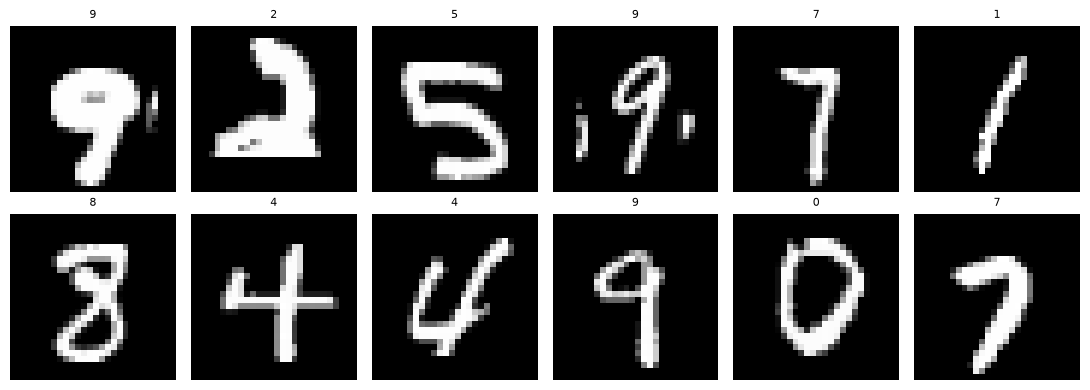

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.ravel(), np.random.choice(len(train_set), 12, replace=False)):
    img, lab = train_set[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## Évaluation et entraînement

Récupérez le code des fonctions `evaluer`et `entrainer` du cours et copiez-les ici.

In [4]:
def evaluer(model, loader):
    """ Retourne la précision du modèle sur le dataset loader, 
    c'est-à-dire nombre de bonnes prédictions / nombre prédictions"""
    correct = 0
    total = 0
    with torch.no_grad(): # pas de rétropropagation sur ces instructions 
        for x, y in loader:
            x, y = x.to(device), y.to(device) # On envoie sur gpu
            scores = model(x) # Passe forward : on obtient les scores pour chaque chiffre
            pred = scores.argmax(dim=1) # retourne l'indice correspondant au score max, donc le chiffre prédit
                                        # Attention : on travaille par batch donc on a l'indice pour chaque élément
                                        # du batch
            correct += (pred == y).sum().item() # on compte le nombre de fois où la prédiction = label
            total += y.size(0) # taille du batch
    return correct / total


def entrainer(model, train_loader, epochs=10):
    """Boucle d'entraînement.
    Affiche la valeur de la loss d'entraînement à chaque itération.
    Affiche le temps d'entraînement à la fin.
    """
    model = model.to(device) # On met le modèle sur GPU
    opt = torch.optim.Adam(model.parameters()) # On utilise Adam pour l'optimisation
    loss_function = nn.CrossEntropyLoss(reduction="sum") # critère d'évaluation : loss utilisée
    
    t0 = time.time()
    # Pour chaque époque
    for ep in range(1, epochs + 1):
        somme, n = 0.0, 0

        # Pour chaque batch
        for x, y in train_loader:
            x, y = x.to(device), y.to(device) # copie du batch sur GPU (si dispo)
            opt.zero_grad() # on remet à 0 les gradients
            loss = loss_function(model(x), y) # on calcule la loss
            loss.backward() # on rétropropage
            opt.step() # on met à jour les paramètres de l'optimiseur
            somme += loss.item() # On calcule la loss sur le dataset entier
            n += y.size(0)
        print(f"epoque {ep:2d}/{epochs} - loss {somme/n:.4f}")

    duree = time.time() - t0
    print(f"Entraînement termine en {duree:.1f}s")

## Question : Perceptron multicouches


Définissez un perceptron multicouches. On supposera qu'il contient deux couches cachées de dimension respectives 256 et 128.

In [5]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__() # on appelle le constructeur de la classe nn.Module
    
        self.neuralNetwork = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784,256),
            nn.ReLU(),
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Linear(128,10)
        )

    def forward(self, x):
        return self.neuralNetwork(x)


## Question : nombre de paramètres

Combien de paramètres a ce réseau de neurones ?

In [6]:
print(784 * 256 + 256 + 256 * 128 + 128 + 128*10 + 10) # nombre de paramètres du modèle

235146


**Réponse :** Écrire votre réponse ici.




## Entraînement

Entraînez votre modèle sur 10 époques. Quelle précision a-t-il ? Que se passe-t-il si on l'entraîne sur 20 époques ?

In [7]:
model = MLP()
entrainer(model, train_loader)
print("Précision sur le train :", evaluer(model, train_loader))


epoque  1/10 - loss 0.4537
epoque  2/10 - loss 0.1773
epoque  3/10 - loss 0.1187
epoque  4/10 - loss 0.0898
epoque  5/10 - loss 0.0695
epoque  6/10 - loss 0.0525
epoque  7/10 - loss 0.0434
epoque  8/10 - loss 0.0359
epoque  9/10 - loss 0.0286
epoque 10/10 - loss 0.0229
Entraînement termine en 28.1s
Précision sur le train : 0.9941166666666666


## Classification d'images translatées

Le perceptron multicouches défini est très précis pour classer les images. Qu'en est-il si les images qu'il doit classer sont décalées verticalement et/ou horizontalement sans que le chiffre soit rogné ?

Pour cela, on propose d'évaluer la précision du même modèle, **sans le réentraîner**, sur le même dataset de test mais modifié de telle manière que les images soient décalées.
On donne le code pour créer, à partir du dataset de test, un deuxième dataset dans lequel les images sont décalées sans que les chiffres soient rognés.

In [8]:
from torch.utils.data import TensorDataset

def shift_images(images):
    """
    images    : tableau (N, H, W), fond noir = 0
                N : nombre d'images, H : hauteur, W : largeur
    max_shift : amplitude maximale du décalage en pixels (None = tout l'espace libre)
    Retourne un tableau de même forme avec chaque chiffre décalé aléatoirement,
    sans jamais rogner le chiffre.
    """
    rng = np.random.default_rng()
    images = np.asarray(images)
    out = np.empty_like(images)
    N, H, W = images.shape

    for i in range(N):
        img = images[i]
        rows = np.flatnonzero(img.max(axis=1) > 0)   # lignes contenant du chiffre
        cols = np.flatnonzero(img.max(axis=0) > 0)   # colonnes contenant du chiffre

        if len(rows) == 0:                            # image entièrement noire
            out[i] = img
            continue

        # décalages possibles pour que le chiffre reste dans l'image
        dy_min, dy_max = -rows[0], H - 1 - rows[-1]
        dx_min, dx_max = -cols[0], W - 1 - cols[-1]



        dy = rng.integers(dy_min, dy_max + 1)
        dx = rng.integers(dx_min, dx_max + 1)

        out[i] = np.roll(img, shift=(dy, dx), axis=(0, 1))

    return out

# On crée le dataset de test où les chiffres sont décalés sans être rognés
X = test_set.data.numpy()      # (10000, 28, 28), uint8
y = test_set.targets           # (10000,)
X_shifted = shift_images(X)
X_shifted = torch.from_numpy(X_shifted).float().div(255).unsqueeze(1)

shifted_set = TensorDataset(X_shifted, y)
shifted_loader = DataLoader(shifted_set, batch_size=batch_size, shuffle=False)

### Affichage de quelques images décalées

On affiche 12 images du dataset de test et les mêmes images décalées.

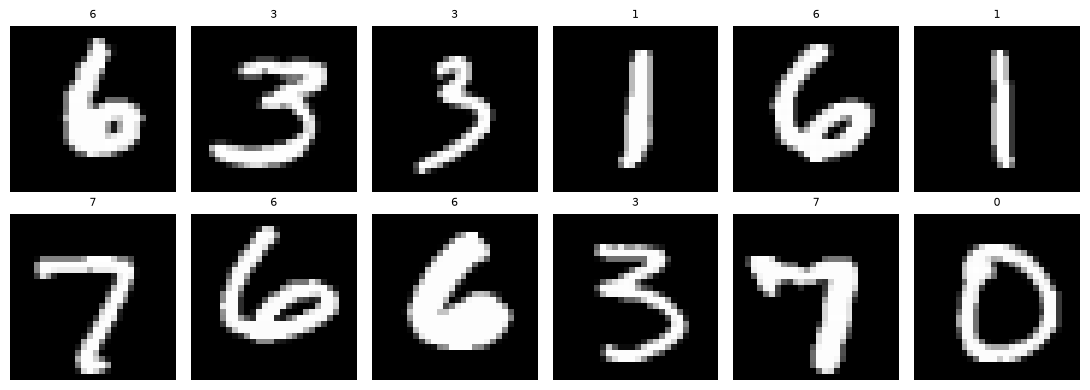

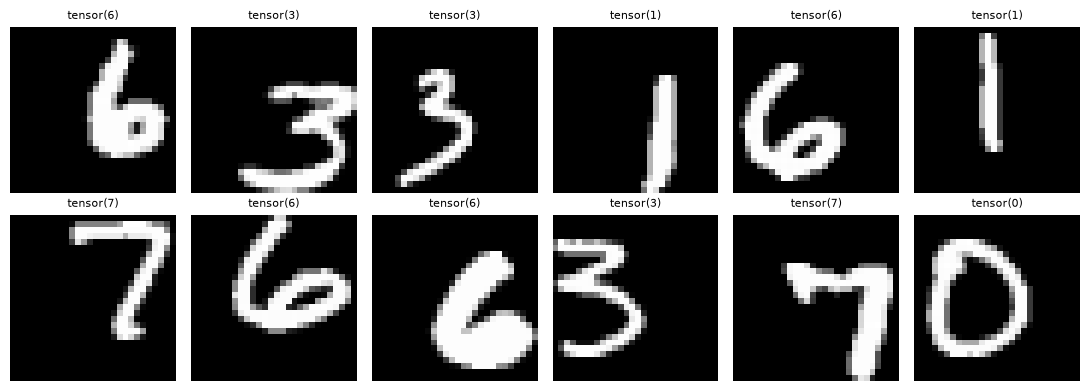

In [9]:
# Choix aléatoire d'images
alea = np.random.choice(len(test_set), 12, replace=False)

# Plot d'images du dataset de test
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.ravel(), alea):
    img, lab = test_set[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

#plot d'images du dataset modifié shifted_set
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.ravel(), alea):
    img, lab = shifted_set[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()



## Question : Évaluation du perceptron multicouches sur le dataset décalé

Évaluez la précision du modèle sur le dataset `shifted_loader`. Qu'est-ce qui se passe au niveau de la précision ? Que se passe-t-il si je double la dimension de chaque couche cachée ? Pourquoi ? Que peut-on conclure de la translation d'images pour un perceptron multicouches ? 

In [10]:
print("Précision sur le test :", evaluer(model, shifted_loader))

Précision sur le test : 0.3374


## Pour aller plus loin

Vous pouvez approfondir ce tp en répondant à ces différentes questions.

### Réaliser une tâche de classification plus difficile

Le dataset MNIST est relativement simple et presque tous les modèles d'apprentissage arrivent à donner de bons résultats. 
Il peut être intéressant de travailler sur un dataset plus difficile. On peut par exemple entraîner et tester le modèle sur MNIST-1D ou Fashion-MNIST. 

**Remarque :** Il existe évidemment bien d'autres datasets mais ils sont beaucoup plus grands. Cela nécessite beaucoup plus d'espace et de temps pour l'entraînement.

#### Dataset MNIST-1D

Ce dataset a été créé de manière à ce que la classification soit plus difficile mais que l'entraînement soit très rapide. C'est encore une classification de chiffre mais chaque entrée correspond à un vecteur de taille 40. Pour plus d'information, voir [ici](https://github.com/greydanus/mnist1d).

Pour l'utiliser, il faut d'abord l'installer avec la commande suivante :

In [11]:
!python -m pip install git+https://github.com/greydanus/mnist1d.git@master

  Cloning https://github.com/greydanus/mnist1d.git (to revision master) to C:\Users\jeanb\AppData\Local\Temp\pip-req-build-5irtkg48
  Resolved https://github.com/greydanus/mnist1d.git to commit e2f536fa86442c13473b433d579e9852ec4d1c1d
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/greydanus/mnist1d.git 'C:\Users\jeanb\AppData\Local\Temp\pip-req-build-5irtkg48'


On peut ensuite générer un dataset de la manière suivante : 

In [12]:
from mnist1d.data import get_dataset_args, get_dataset
args = get_dataset_args()
data = get_dataset(args, download=False, regenerate=True)

x_train = torch.tensor(data["x"], dtype=torch.float32)
y_train = torch.tensor(data["y"], dtype=torch.long)
x_test  = torch.tensor(data["x_test"], dtype=torch.float32)
y_test  = torch.tensor(data["y_test"], dtype=torch.long)

# Création des datasets
train_dataset = TensorDataset(x_train, y_train)
test_dataset  = TensorDataset(x_test, y_test)

Did or could not load data from ./mnist1d_data.pkl. Rebuilding dataset...


In [14]:
print(x_train.shape[1], y_train.shape, x_test.shape, y_test.shape)

40 torch.Size([4000]) torch.Size([1000, 40]) torch.Size([1000])


In [16]:
# Adapter le modèle à la taille des entrées du dataset MNIST-1D
model_mnist1d = MLP()
model_mnist1d.neuralNetwork = nn.Sequential(
    nn.Linear(x_train.shape[1], 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

train_loader_mnist1d = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader_mnist1d = DataLoader(test_dataset, batch_size=64, shuffle=False)
entrainer(model_mnist1d, train_loader_mnist1d)
# `train_dataset` est un TensorDataset, pas un DataLoader.
# On utilise donc le DataLoader déjà créé pour l'entraînement.
print("Précision sur le train :", evaluer(model_mnist1d, train_loader_mnist1d))
print("Précision sur le test :", evaluer(model_mnist1d, test_loader_mnist1d))

epoque  1/10 - loss 1.9448
epoque  2/10 - loss 1.6360
epoque  3/10 - loss 1.4649
epoque  4/10 - loss 1.3135
epoque  5/10 - loss 1.2097
epoque  6/10 - loss 1.1215
epoque  7/10 - loss 1.0468
epoque  8/10 - loss 0.9797
epoque  9/10 - loss 0.9185
epoque 10/10 - loss 0.8681
Entraînement termine en 1.0s
Précision sur le train : 0.72175
Précision sur le test : 0.576


#### Dataset Fashion-MNIST

C'est un dataset constitué de petites images en noir et blanc représentant des vêtements, chaussures et sacs au même format que dans MNIST. Il faut déterminer ce que représente chaque image (10 classes possibles). Plus d'information [ici](https://github.com/zalandoresearch/fashion-mnist). 

Il est possible d'utiliser le dataset de la manière suivante : 

In [17]:
train_set = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

In [18]:
# MLP() contient déjà Flatten() et une première couche de 784 entrées
model_fashionmnist = MLP()

train_loader_fashionmnist = DataLoader(
    train_set, batch_size=64, shuffle=True
)
test_loader_fashionmnist = DataLoader(
    test_set, batch_size=64, shuffle=False
)

entrainer(model_fashionmnist, train_loader_fashionmnist)
print("Précision sur le train :", evaluer(model_fashionmnist, train_loader_fashionmnist))
print("Précision sur le test :", evaluer(model_fashionmnist, test_loader_fashionmnist))

epoque  1/10 - loss 0.5266
epoque  2/10 - loss 0.3686
epoque  3/10 - loss 0.3308
epoque  4/10 - loss 0.3093
epoque  5/10 - loss 0.2897
epoque  6/10 - loss 0.2738
epoque  7/10 - loss 0.2596
epoque  8/10 - loss 0.2482
epoque  9/10 - loss 0.2373
epoque 10/10 - loss 0.2267
Entraînement termine en 35.7s
Précision sur le train : 0.92015
Précision sur le test : 0.8863


### Modifier les hyperparamètres

Il est possible de modifier les hyperparamètres de votre modèle : nombre de couches cachées et dimension de chaque couche. Cela change-t-il les performances sur les nouveaux datasets ?

### Tracer des courbes

Généralement, il est intéressant de visualiser l'évolution de certaines données durant l'entraînement. On peut vouloir tracer la courbe de la loss à chaque époque de l'entraînement. On peut aussi tracer la courbe de la précision du modèle sur le dataset d'entraînement et le dataset de test pour voir la corrélation entre la diminution de la loss et l'augmentation de la précision.

Pour tracer une courbe, on peut utiliser la librairie `matplotlib`. Voici un exemple d'utilisation :

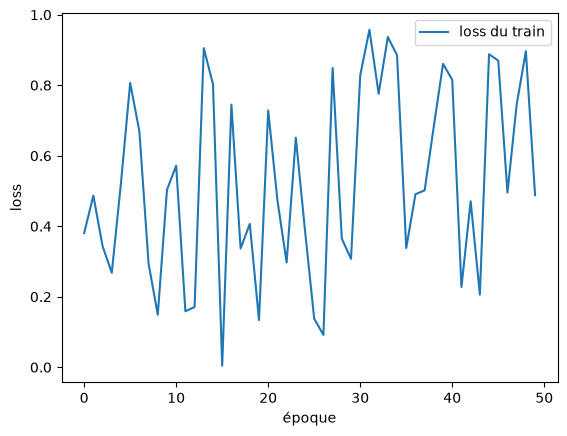

In [ ]:
import matplotlib.pyplot as plt

# Fake data
epoques = np.array(range(50))
loss = np.random.rand(len(epoques))

# On trace la courbe : abscisse : époque, ordonnée : loss
plt.plot(loss, label="loss du train")
plt.xlabel("époque"); plt.ylabel("loss"); plt.legend()
plt.show()

Sur les différents datasets, la loss et la précision sur le dataset sont-ils corrélés ? Pourquoi ?